### 💡 Hard Margin & Soft Margin
SVM은 마진을 최대한 크게 확보하는 결정 경계를 찾는다.

그렇지만 실제 데이터에서는 모든 데이터를 완벽하기 분류하기 어려울 때가 있다. 이 문제를 처리하기 위해 `Hard Margin`과 `Soft Margin`의 이해가 필요하다.

#### 1️⃣ Hard Margin

하드 마진은 모든 학습 데이터를 정확하게 분류하면서, 어떤 데이터도 마진 내부에 들어오지 않도록 하는 방식이다.

즉, 두 가지 조건을 만족해야 한다.
- 모든 학습 데이터를 올바르게 분류해야 한다.
- 모든 학습 데이터가 마진 경계 위 또는 바깥쪽에 있어야 한다.

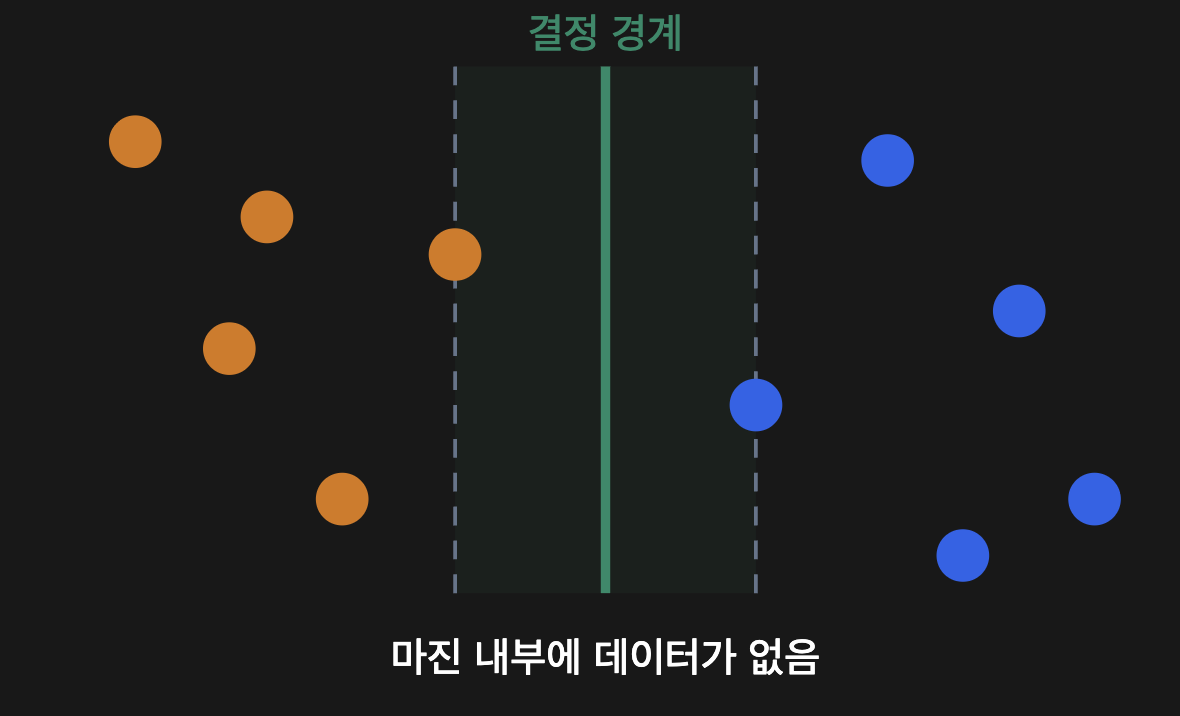

하지만 실제로는 현실에서 데이터가 항상 깔끔하게 나눠지지는 않는다.

예를 들어 시험 합격 여부를 예측할 때 공부시간이 아무리 길어도 불합격하는 학생이 생길 수 있다.

이런 데이터까지 모두 완벽하게 분류하려고 하면 경계를 만들 수 없거나, 일부 데이터에 지나치게 민감해질 수 있다.

#### 2️⃣ Soft Margin

소프트 마진은 일부 데이터의 마진 침법이나 잘못된 분류를 허용하면서 결정 경계를 학습하는 방식이다.

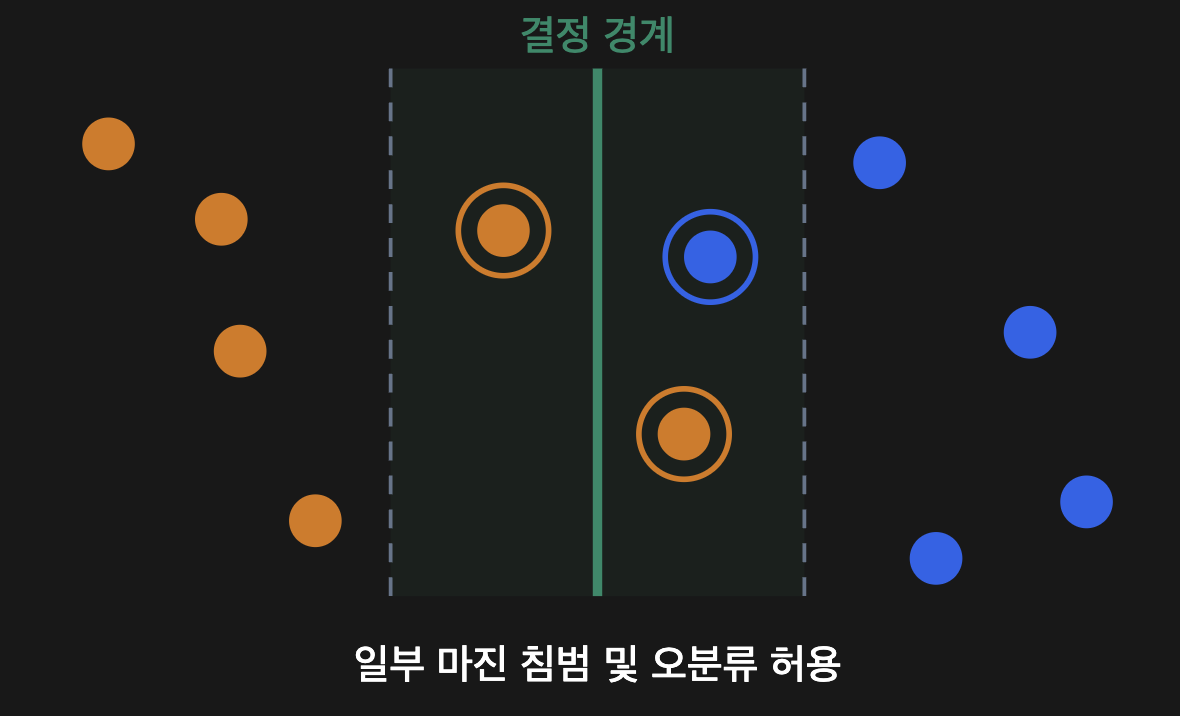

소프트 마진은 아래 두 가지를 함께 고려한다.
- 마진을 최대한 넓게 확보하기
- 마진 위반과 분류 오류를 줄이기

`scikit-learn`의 `SVC`는 **디폴트가 소프트 마진 방식**이다.

`C`를 아주 크게 설정하면 하드 마진에 가까운 동작을 유도할 수 있지만, 하드 마진과 완전히 동일한 것은 아니다.

#### 3️⃣ 하이퍼파라미터 `C`
소프트 마진 SVM에서는 마진을 넓게 확보하는 것과 마진 위반을 줄이는 것 사이에 균형이 필요하다.

이 균형을 조절하는 하이퍼파라미터가 `C`이다. `C`값이 클수록 소프트 마진에서 하드 마진으로 설정된다고 보면 된다.

`C`값이 커질수록 하드 마진의 패턴이 되기 때문에 과적합이 발생할 가능성이 점점 커진다.

그래서 적절한 `C`값은 학습 데이터만 보고 결정하는 것이 아니라, 검증 데이터를 이용해 선택하는 것이 좋다.

In [ ]:
# C값 비교해보기
import numpy as np
from sklearn.svm import SVC

X = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)

# 7시간 공부한 학생은 불합격
y = np.array([0, 0, 0, 0, 1, 1, 0, 1])

# C가 작은 모델
model_small = SVC(kernel="linear", C=0.1)

# C가 큰 모델
model_large = SVC(kernel="linear", C=100)

# 모델 학습
model_small.fit(X, y)
model_large.fit(X,y)

print("실제 정답:")
print(y)

print("C=0.1 예측:")
print(model_small.predict(X))

print("C=100 예측:")
print(model_large.predict(X))

print("C=0.1 서포트 벡터:")
print(model_small.support_vectors_)

print("C=100 서포트 벡터:")
print(model_large.support_vectors_)

print("C=0.1 서포트 벡터 개수:")
print(len(model_small.support_))

print("C=100 서포트 벡터 개수:")
print(len(model_large.support_))

실제 정답:
[0 0 0 0 1 1 0 1]
C=0.1 예측:
[0 0 0 0 0 1 1 1]
C=100 예측:
[0 0 0 0 0 1 1 1]
C=0.1 서포트 벡터:
[[3.]
 [4.]
 [7.]
 [5.]
 [6.]
 [8.]]
C=100 서포트 벡터:
[[3.]
 [4.]
 [7.]
 [5.]
 [6.]
 [8.]]
C=0.1 서포트 벡터 개수:
6
C=100 서포트 벡터 개수:
6


---
#### 실습 문제

In [ ]:
import numpy as np
from sklearn.svm import SVC

X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([0, 0, 0, 0, 1, 1, 0, 1, 1, 1])

# 1. C=0.01인 선형 SVM 모델 생성 및 학습
model_small = SVC(kernel="linear", C=0.01)
model_small.fit(X, y)

# 2. C=100인 선형 SVM 모델 생성 및 학습
model_large = SVC(kernel="linear", C=100)
model_large.fit(X, y)

# 3. 두 모델의 학습 데이터 예측 결과 출력
print(f"model_small pred : {model_small.predict(X)}")
print(f"model_large pred : {model_large.predict(X)}")

# 4. 두 모델의 서포트 벡터 출력
print(f"model_small support vector : {model_small.support_vectors_}")
print(f"model_large support vector : {model_large.support_vectors_}")

# 5. 두 모델의 서포트 벡터 개수 출력
print(f"model_small support vector count : {model_small.n_support_}")
print(f"model_large support vector count : {model_large.n_support_}")

X_new = np.array([[3], [5], [7], [9]])

# 1. C=0.01 모델의 decision_function() 점수 출력
print(model_small.decision_function(X_new))

# 2. C=100 모델의 decision_function() 점수 출력
print(model_large.decision_function(X_new))

# 3. 두 모델의 predict() 결과 비교
print(model_small.predict(X_new))
print(model_large.predict(X_new))

# 4. C 값이 달라지면 결정 함수 점수도
#    달라질 수 있는 이유를 주석으로 설명
# -> C값에 따라서 마진의 크기가 달라지기 때문에 결정 함수 점수또한 달라진ㄷ나.

model_small pred : [0 0 0 0 0 1 1 1 1 1]
model_large pred : [0 0 0 0 0 1 1 1 1 1]
model_small support vector : [[ 1.]
 [ 2.]
 [ 3.]
 [ 4.]
 [ 7.]
 [ 5.]
 [ 6.]
 [ 8.]
 [ 9.]
 [10.]]
model_large support vector : [[3.]
 [4.]
 [7.]
 [5.]
 [6.]
 [8.]]
model_small support vector count : [5 5]
model_large support vector count : [3 3]
[-0.525 -0.105  0.315  0.735]
[-1.  -0.2  0.6  1.4]
[0 0 1 1]
[0 0 1 1]
